# CAFA 6 - 계층적 다중 라벨 분류 모델 구축

## 목표
- ESM2 임베딩을 입력으로 받아 GO Terms를 예측하는 딥러닝 모델 구축
- 계층 구조 제약조건 적용 (자식 점수 ≤ 부모 점수)

In [1]:
# 필수 패키지 설치
# 이미 설치되어 있으면 건너뜁니다.

import sys
import subprocess

def install_package(package):
    """패키지가 없으면 설치"""
    try:
        __import__(package.split('[')[0].split('==')[0])
        print(f"✓ {package} already installed")
    except ImportError:
        print(f"Installing {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])
        print(f"✓ {package} installed successfully")

# 필수 패키지 목록
required_packages = [
    "numpy>=1.21.0",
    "pandas>=1.3.0",
    "torch>=2.0.0",
    "torchvision>=0.15.0",
    "scipy>=1.7.0",
    "scikit-learn>=1.0.0",
    "tqdm>=4.62.0",
    "matplotlib>=3.4.0",
    "seaborn>=0.11.0",
    "biopython>=1.79"
]

print("=" * 60)
print("패키지 설치 확인 중...")
print("=" * 60)

for package in required_packages:
    install_package(package)

print("\n" + "=" * 60)
print("✅ 모든 패키지 설치 완료!")
print("=" * 60)

# 버전 확인
import numpy as np
import pandas as pd
import torch
import scipy
import sklearn
import matplotlib
import seaborn as sns
from Bio import SeqIO

print(f"\n📊 설치된 패키지 버전:")
print(f"  - NumPy: {np.__version__}")
print(f"  - Pandas: {pd.__version__}")
print(f"  - PyTorch: {torch.__version__}")
print(f"  - SciPy: {scipy.__version__}")
print(f"  - Scikit-learn: {sklearn.__version__}")
print(f"  - Matplotlib: {matplotlib.__version__}")
print(f"  - Seaborn: {sns.__version__}")
print(f"  - Biopython: (installed)")

# GPU 확인
if torch.cuda.is_available():
    print(f"\n🚀 GPU 사용 가능: {torch.cuda.get_device_name(0)}")
    print(f"   CUDA Version: {torch.version.cuda}")
else:
    print(f"\n💻 CPU 모드로 실행됩니다.")

print("\n✅ 환경 설정이 완료되었습니다. 다음 셀로 진행하세요!")

패키지 설치 확인 중...
Installing numpy>=1.21.0...
✓ numpy>=1.21.0 installed successfully
Installing pandas>=1.3.0...



[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip

[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip


✓ pandas>=1.3.0 installed successfully
Installing torch>=2.0.0...



[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip


✓ torch>=2.0.0 installed successfully
Installing torchvision>=0.15.0...



[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip


... (9 outputs left out)


[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip


✓ seaborn>=0.11.0 installed successfully
Installing biopython>=1.79...



[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip


✓ biopython>=1.79 installed successfully

✅ 모든 패키지 설치 완료!

📊 설치된 패키지 버전:
  - NumPy: 1.26.3
  - Pandas: 2.3.3
  - PyTorch: 2.4.1+cu124
  - SciPy: 1.16.3
  - Scikit-learn: 1.8.0
  - Matplotlib: 3.10.8
  - Seaborn: 0.13.2
  - Biopython: (installed)

🚀 GPU 사용 가능: NVIDIA RTX 4000 Ada Generation
   CUDA Version: 12.4

✅ 환경 설정이 완료되었습니다. 다음 셀로 진행하세요!


## 🔧 환경별 경로 설정 가이드

이 노트북을 다른 환경에서 실행할 때 **경로를 수정**해야 합니다:

### 옵션 1: 로컬 환경
```python
BASE_DIR = Path(r"c:\workspace\CAFA_6")  # Windows
# 또는
BASE_DIR = Path("/home/user/CAFA_6")    # Linux/Mac
```

### 옵션 2: Google Colab
```python
from google.colab import drive
drive.mount('/content/drive')
BASE_DIR = Path('/content/drive/MyDrive/CAFA_6')
```

### 옵션 3: Kaggle
```python
BASE_DIR = Path('/kaggle/input/cafa-6')
```

### 옵션 4: 현재 디렉토리 기준 (권장)
```python
BASE_DIR = Path.cwd()  # 노트북이 있는 디렉토리
# 또는
BASE_DIR = Path.cwd().parent  # 상위 디렉토리
```

**아래 셀에서 환경에 맞게 BASE_DIR을 설정하세요!**

# CAFA 6 - 계층적 다중 라벨 분류 모델 구축

## 목표
- ESM2 임베딩을 입력으로 받아 GO Terms를 예측하는 딥러닝 모델 구축
- 계층 구조 제약조건 적용 (자식 점수 ≤ 부모 점수)

In [2]:
%pip install h5py
import numpy as np
import pandas as pd
import pickle
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy.sparse import load_npz, csr_matrix
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import os
import h5py  # HDF5 파일 지원 추가

# GPU 설정
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# ==========================================
# 📂 경로 설정 (환경에 맞게 수정하세요!)
# ==========================================

# 옵션 1: 현재 작업 디렉토리 기준 (권장)
try:
    # Jupyter 노트북에서 실행 중인 경우
    BASE_DIR = Path(r"/workspace/CAFA_6_hjs")
    # 노트북이 scripts 폴더에 있는 경우 상위 디렉토리로 이동
    if BASE_DIR.name == 'scripts':
        BASE_DIR = BASE_DIR.parent
except:
    pass

# 옵션 2: 절대 경로 지정 (필요시 아래 주석 해제하고 수정)
# BASE_DIR = Path(r"c:\workspace\CAFA_6")  # Windows
# BASE_DIR = Path("/home/user/CAFA_6")    # Linux/Mac
# BASE_DIR = Path("/content/drive/MyDrive/CAFA_6")  # Google Colab

# 옵션 3: Google Colab에서 실행하는 경우
# from google.colab import drive
# drive.mount('/content/drive')
# BASE_DIR = Path('/content/drive/MyDrive/CAFA_6')

# 옵션 4: Kaggle에서 실행하는 경우
# BASE_DIR = Path('/kaggle/input/cafa-6')

# 하위 디렉토리 설정
# HDF5 임베딩 파일 경로 (새로운 ESM2 토큰화 임베딩)
EMBED_DIR = BASE_DIR / "embedded_fasta_for_1dcnn"
TRAIN_H5_PATH = EMBED_DIR / "train" / "train_embeddings_82404sq.h5"
TEST_H5_PATH = EMBED_DIR / "test" / "test_embeddings_200sq.h5"

GO_DIR = BASE_DIR / "go_basic"
DATA_DIR = BASE_DIR / "cafa-6-protein-function-prediction"

# 경로 검증
print(f"\n📂 경로 설정:")
print(f"  BASE_DIR: {BASE_DIR}")
print(f"  존재 여부: {BASE_DIR.exists()}")

if not BASE_DIR.exists():
    print(f"\n⚠️  경로를 찾을 수 없습니다!")
    print(f"   현재 작업 디렉토리: {Path.cwd()}")
    print(f"\n💡 해결 방법:")
    print(f"   1. 위 셀에서 BASE_DIR을 올바른 경로로 수정하세요.")
    print(f"   2. 또는 노트북을 올바른 위치로 이동하세요.")
else:
    print(f"\n✅ 필수 디렉토리 확인:")
    print(f"  - embedded_fasta_for_1dcnn: {EMBED_DIR.exists()}")
    print(f"  - Train H5: {TRAIN_H5_PATH.exists()}")
    print(f"  - Test H5: {TEST_H5_PATH.exists()}")
    print(f"  - go_basic: {GO_DIR.exists()}")
    print(f"  - cafa-6-protein-function-prediction: {DATA_DIR.exists()}")

print('\n✅ 환경 설정 완료!')


[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Using device: cuda

📂 경로 설정:
  BASE_DIR: /workspace/CAFA_6_hjs
  존재 여부: True

✅ 필수 디렉토리 확인:
  - embedded_fasta_for_1dcnn: True
  - Train H5: True
  - Test H5: True
  - go_basic: True
  - cafa-6-protein-function-prediction: True

✅ 환경 설정 완료!


## 1. 데이터 로드 및 탐색

In [3]:
# =========================================================================
# HDF5 임베딩 메타데이터 로드 (1D CNN용) - 모듈 사용
# =========================================================================
# h5_data_loder 모듈의 H5MetadataAnalyzer 클래스를 사용하여
# HDF5 파일에서 메타데이터를 로드합니다.
# =========================================================================

import sys
import importlib

# python_scripts 모듈 경로 추가
sys.path.insert(0, str(BASE_DIR / "python_scripts"))

# 모듈 import (변경사항 반영을 위해 reload)
import h5_data_loder
importlib.reload(h5_data_loder)
from h5_data_loder import H5MetadataAnalyzer, H5MultiDatasetAnalyzer, HDF5EmbeddingDataset

# 1D CNN 설정
MAX_SEQ_LENGTH = H5MetadataAnalyzer.DEFAULT_MAX_SEQ_LENGTH  # 1024
EMBEDDING_DIM = H5MetadataAnalyzer.DEFAULT_EMBEDDING_DIM    # 1280

# =========================================================================
# Train/Test 메타데이터 로드 (H5MultiDatasetAnalyzer 사용)
# =========================================================================
print("=" * 70)
print("🚀 HDF5 메타데이터 로드 시작 (1D CNN 모드)")
print("=" * 70)

# 멀티 데이터셋 분석기 생성
multi_analyzer = H5MultiDatasetAnalyzer()

# Train 메타데이터 로드
print("\n[1/2] Train 데이터:")
train_analyzer = multi_analyzer.add_dataset('train', TRAIN_H5_PATH)

# Test 메타데이터 로드
print("\n[2/2] Test 데이터:")
test_analyzer = multi_analyzer.add_dataset('test', TEST_H5_PATH)

# 기존 코드 호환성을 위한 변수 할당
train_metadata = train_analyzer.metadata
train_ids_raw = train_analyzer.ids_raw
train_offsets = train_analyzer.offsets
train_lengths = train_analyzer.lengths
train_ids = train_analyzer.ids  # 이미 파싱된 ID

test_metadata = test_analyzer.metadata
test_ids_raw = test_analyzer.ids_raw
test_offsets = test_analyzer.offsets
test_lengths = test_analyzer.lengths
test_ids = test_analyzer.ids  # 이미 파싱된 ID

# 요약 출력
print("\n" + "=" * 70)
print("📊 로드 완료 요약")
print("=" * 70)
print(f"Train 시퀀스 수: {train_analyzer.num_sequences:,}")
print(f"Train 총 토큰 수: {train_analyzer.total_tokens:,}")
print(f"Test 시퀀스 수: {test_analyzer.num_sequences:,}")
print(f"Test 총 토큰 수: {test_analyzer.total_tokens:,}")
print(f"임베딩 차원: {EMBEDDING_DIM}")
print(f"최대 시퀀스 길이: {MAX_SEQ_LENGTH}")

print(f"\n🔍 ID 파싱 완료:")
print(f"  원본 ID 샘플: {train_ids_raw[0]}")
print(f"  파싱된 ID 샘플: {train_ids[0]}")

# 시퀀스 길이 통계 출력
train_stats = train_analyzer.get_length_statistics()
test_stats = test_analyzer.get_length_statistics()
print(f"\n📊 시퀀스 길이 분포:")
print(f"  Train - min: {train_stats['min']}, max: {train_stats['max']}, mean: {train_stats['mean']:.1f}")
print(f"  Test  - min: {test_stats['min']}, max: {test_stats['max']}, mean: {test_stats['mean']:.1f}")

🚀 HDF5 메타데이터 로드 시작 (1D CNN 모드)

[1/2] Train 데이터:
HDF5 메타데이터 로드 중: /workspace/CAFA_6_hjs/embedded_fasta_for_1dcnn/train/train_embeddings_82404sq.h5
   시퀀스 수: 82,404
   총 토큰 수: 43,327,058
   임베딩 차원: 1280
   평균 시퀀스 길이: 525.8
   메타데이터 로드 완료

[2/2] Test 데이터:
HDF5 메타데이터 로드 중: /workspace/CAFA_6_hjs/embedded_fasta_for_1dcnn/test/test_embeddings_200sq.h5
   시퀀스 수: 200
   총 토큰 수: 98,187
   임베딩 차원: 1280
   평균 시퀀스 길이: 490.9
   메타데이터 로드 완료

📊 로드 완료 요약
Train 시퀀스 수: 82,404
Train 총 토큰 수: 43,327,058
Test 시퀀스 수: 200
Test 총 토큰 수: 98,187
임베딩 차원: 1280
최대 시퀀스 길이: 1024

🔍 ID 파싱 완료:
  원본 ID 샘플: b'sp|A0A0C5B5G6|MOTSC_HUMAN'
  파싱된 ID 샘플: A0A0C5B5G6

📊 시퀀스 길이 분포:
  Train - min: 3, max: 35213, mean: 525.8
  Test  - min: 16, max: 1022, mean: 490.9


In [4]:
# =========================================================================
# 임베딩 로드 테스트 (HDF5 압축 구조 확인)
# =========================================================================
# HDF5 파일 구조:
# ├── embeddings (N_total_tokens, 1280) float16  # 모든 토큰 연속 저장
# ├── offsets (num_sequences,) int64             # 각 시퀀스 시작 위치
# ├── lengths (num_sequences,) int32             # 각 시퀀스 실제 길이
# └── ids (num_sequences,) string                # 단백질 ID
#
# 임베딩 접근 방법:
#   offset = offsets[idx]
#   length = lengths[idx]
#   embedding = embeddings[offset:offset+length]  # (length, 1280)
# =========================================================================

print("=" * 70)
print("🧪 임베딩 로드 테스트")
print("=" * 70)

# 첫 번째 시퀀스 임베딩 로드
embedding, protein_id = train_analyzer.load_embedding_by_index(0)

print(f"\n📊 첫 번째 시퀀스 임베딩:")
print(f"   Protein ID: {protein_id}")
print(f"   Embedding shape: {embedding.shape}")
print(f"   Dtype: {embedding.dtype}")
print(f"   Memory: {embedding.nbytes / 1024:.2f} KB")

# 임베딩 값 통계
print(f"\n📈 임베딩 값 통계:")
print(f"   Min: {embedding.min():.4f}")
print(f"   Max: {embedding.max():.4f}")
print(f"   Mean: {embedding.mean():.4f}")
print(f"   Std: {embedding.std():.4f}")

# 오프셋/길이 확인
print(f"\n🔍 HDF5 구조 확인 (처음 5개 시퀀스):")
print(f"   {'Index':<8} {'Offset':<12} {'Length':<10} {'ID':<15}")
print(f"   {'-'*8} {'-'*12} {'-'*10} {'-'*15}")
for i in range(min(5, len(train_offsets))):
    print(f"   {i:<8} {train_offsets[i]:<12} {train_lengths[i]:<10} {train_ids[i]:<15}")

print(f"\n✅ 임베딩 로드 테스트 완료!")
print("=" * 70)


🧪 임베딩 로드 테스트

📊 첫 번째 시퀀스 임베딩:
   Protein ID: A0A0C5B5G6
   Embedding shape: (16, 1280)
   Dtype: float16
   Memory: 40.00 KB

📈 임베딩 값 통계:
   Min: -7.9727
   Max: 1.6973
   Mean: -0.0018
   Std: 0.2957

🔍 HDF5 구조 확인 (처음 5개 시퀀스):
   Index    Offset       Length     ID             
   -------- ------------ ---------- ---------------
   0        0            16         A0A0C5B5G6     
   1        16           1464       A0JNW5         
   2        1480         581        A0JP26         
   3        2061         232        A0PK11         
   4        2293         786        A1A4S6         

✅ 임베딩 로드 테스트 완료!


In [5]:
# GO Term 매핑 데이터 로드
print("\nGO Term 매핑 데이터 로드 중...")
train_terms_df = pd.read_csv(
    DATA_DIR / "Train" / "train_terms.tsv", 
    sep="\t"
)

# 컬럼명 표준화 (파일의 실제 컬럼명: EntryID, term, aspect)
train_terms_df.columns = ["EntryID", "GO_Term", "Aspect"]

print(f"Train terms 총 개수: {len(train_terms_df)}")
print(f"고유 단백질 개수: {train_terms_df['EntryID'].nunique()}")
print(f"고유 GO Term 개수: {train_terms_df['GO_Term'].nunique()}")
print(f"\nAspect 분포:")
print(train_terms_df['Aspect'].value_counts())
print(f"\n샘플 데이터:")
print(train_terms_df.head(10))


GO Term 매핑 데이터 로드 중...
Train terms 총 개수: 537027
고유 단백질 개수: 82404
고유 GO Term 개수: 26125

Aspect 분포:
Aspect
P    250805
C    157770
F    128452
Name: count, dtype: int64

샘플 데이터:
  EntryID     GO_Term Aspect
0  Q5W0B1  GO:0000785      C
1  Q5W0B1  GO:0004842      F
2  Q5W0B1  GO:0051865      P
3  Q5W0B1  GO:0006275      P
4  Q5W0B1  GO:0006513      P
5  Q5W0B1  GO:0003682      F
6  Q5W0B1  GO:0005515      F
7  Q3EC77  GO:0000138      C
8  Q3EC77  GO:0005794      C
9  Q8IZR5  GO:0005515      F


In [6]:
# GO 계층 구조 데이터 로드
print("\nGO 계층 구조 데이터 로드 중...")
with open(GO_DIR / "go_term_mappings.pkl", "rb") as f:
    go_mappings = pickle.load(f)

print(f"GO mappings keys: {list(go_mappings.keys())}")

# 실제 키 이름 확인 (go_to_idx, idx_to_go)
term_to_idx = go_mappings['go_to_idx']  # GO Term -> Index 매핑
idx_to_term = go_mappings['idx_to_go']  # Index -> GO Term 매핑
num_go_terms = len(term_to_idx)

print(f"GO Term 총 개수: {num_go_terms}")
print(f"샘플 매핑: {list(term_to_idx.items())[:5]}")

# GO ancestor matrix (계층 구조)
ancestor_matrix = load_npz(GO_DIR / "go_ancestor_matrix.npz")
print(f"\nGO ancestor matrix shape: {ancestor_matrix.shape}")
print(f"Sparsity: {1 - ancestor_matrix.nnz / (ancestor_matrix.shape[0] * ancestor_matrix.shape[1]):.4%}")


GO 계층 구조 데이터 로드 중...
GO mappings keys: ['go_to_idx', 'idx_to_go', 'terms']
GO Term 총 개수: 40122
샘플 매핑: [('GO:0000001', 0), ('GO:0000002', 1), ('GO:0000006', 2), ('GO:0000007', 3), ('GO:0000009', 4)]

GO ancestor matrix shape: (40122, 40122)
Sparsity: 99.9753%


In [7]:
# 🔍 디버깅: ID 불일치 원인 파악
print("=" * 80)
print("ID 불일치 디버깅")
print("=" * 80)

print("\n1. Train IDs (임베딩) 샘플:")
print(f"   개수: {len(train_ids)}")
print(f"   타입: {type(train_ids[0])}")
for i in range(min(5, len(train_ids))):
    print(f"   [{i}] {repr(train_ids[i])}")

print("\n2. Train Terms 단백질 ID 샘플:")
unique_protein_ids = train_terms_df['EntryID'].unique()
print(f"   개수: {len(unique_protein_ids)}")
print(f"   타입: {type(unique_protein_ids[0])}")
for i in range(min(5, len(unique_protein_ids))):
    print(f"   [{i}] {repr(unique_protein_ids[i])}")

print("\n3. 직접 비교:")
print(f"   train_ids[0] == unique_protein_ids[0]: {train_ids[0] == unique_protein_ids[0]}")
print(f"   train_ids[0] in unique_protein_ids: {train_ids[0] in unique_protein_ids}")

print("\n4. Set 교집합:")
train_ids_set = set(train_ids)
terms_ids_set = set(unique_protein_ids)
intersection = train_ids_set & terms_ids_set
print(f"   교집합 개수: {len(intersection)}")
if len(intersection) > 0:
    print(f"   교집합 샘플: {list(intersection)[:5]}")

print("\n5. FASTA 파일 ID 확인:")
from Bio import SeqIO
fasta_path = DATA_DIR / "Train" / "train_sequences.fasta"
if fasta_path.exists():
    count = 0
    for record in SeqIO.parse(fasta_path, "fasta"):
        print(f"   FASTA ID: {repr(record.id)}")
        count += 1
        if count >= 3:
            break

print("=" * 80)

ID 불일치 디버깅

1. Train IDs (임베딩) 샘플:
   개수: 82404
   타입: <class 'numpy.str_'>
   [0] 'A0A0C5B5G6'
   [1] 'A0JNW5'
   [2] 'A0JP26'
   [3] 'A0PK11'
   [4] 'A1A4S6'

2. Train Terms 단백질 ID 샘플:
   개수: 82404
   타입: <class 'str'>
   [0] 'Q5W0B1'
   [1] 'Q3EC77'
   [2] 'Q8IZR5'
   [3] 'Q8R2Z3'
   [4] 'P63027'

3. 직접 비교:
   train_ids[0] == unique_protein_ids[0]: False
   train_ids[0] in unique_protein_ids: True

4. Set 교집합:
   교집합 개수: 82404
   교집합 샘플: ['P15455', 'Q78KK3', 'G5ECB1', 'Q12486', 'P0C329']

5. FASTA 파일 ID 확인:
   FASTA ID: 'sp|A0A0C5B5G6|MOTSC_HUMAN'
   FASTA ID: 'sp|A0JNW5|BLT3B_HUMAN'
   FASTA ID: 'sp|A0JP26|POTB3_HUMAN'


## 2. 데이터 전처리 및 라벨 생성

In [8]:
# 단백질 ID를 인덱스로 매핑
print("단백질 ID 매핑 생성 중...")
protein_id_to_idx = {protein_id: idx for idx, protein_id in enumerate(train_ids)}

# train_terms_df를 임베딩 순서에 맞게 정렬
train_terms_df = train_terms_df[train_terms_df['EntryID'].isin(set(train_ids))].copy()
print(f"임베딩과 매칭되는 단백질 수: {train_terms_df['EntryID'].nunique()}")

단백질 ID 매핑 생성 중...
임베딩과 매칭되는 단백질 수: 82404


In [9]:
# Multi-label binary matrix 생성
print("\nMulti-label binary matrix 생성 중...")
num_proteins = len(train_ids)
label_matrix = np.zeros((num_proteins, num_go_terms), dtype=np.float32)

for _, row in tqdm(train_terms_df.iterrows(), total=len(train_terms_df), desc="라벨 매트릭스 구축"):
    protein_id = row['EntryID']
    go_term = row['GO_Term']
    
    if protein_id in protein_id_to_idx and go_term in term_to_idx:
        protein_idx = protein_id_to_idx[protein_id]
        go_idx = term_to_idx[go_term]
        label_matrix[protein_idx, go_idx] = 1.0

print(f"Label matrix shape: {label_matrix.shape}")
print(f"Total positive labels: {label_matrix.sum():.0f}")
print(f"Sparsity: {1 - label_matrix.sum() / label_matrix.size:.4%}")
print(f"Labels per protein (mean): {label_matrix.sum(axis=1).mean():.2f}")
print(f"Labels per protein (median): {np.median(label_matrix.sum(axis=1)):.2f}")


Multi-label binary matrix 생성 중...


라벨 매트릭스 구축:   0%|          | 0/537027 [00:00<?, ?it/s]

Label matrix shape: (82404, 40122)
Total positive labels: 537027
Sparsity: 99.9838%
Labels per protein (mean): 6.52
Labels per protein (median): 4.00


In [13]:
import torch
import numpy as np
import scipy.sparse as sp
import time
import gc

def scipy_to_torch_sparse(scipy_mat):
    """
    Converts a Scipy sparse matrix or Numpy array to a PyTorch sparse tensor.
    """
    import scipy.sparse as sp
    
    if not sp.issparse(scipy_mat):
        coo = sp.coo_matrix(scipy_mat)
    else:
        coo = scipy_mat.tocoo()
    
    values = coo.data
    indices = np.vstack((coo.row, coo.col))
    
    i = torch.LongTensor(indices)
    v = torch.FloatTensor(values)
    shape = coo.shape
    
    return torch.sparse_coo_tensor(i, v, torch.Size(shape)).coalesce()

def propagate_labels_gpu(label_matrix, ancestor_matrix, batch_size=2048):
    """
    Performs label propagation using GPU acceleration with Batch Processing.
    
    Principle:
    Instead of multiplying the entire matrix at once (which causes OOM),
    we slice the proteins (rows) into batches, compute on GPU, and move results to CPU.
    
    Args:
        label_matrix: Scipy sparse matrix (Proteins x Labels)
        ancestor_matrix: Scipy sparse matrix (Labels x Labels)
        batch_size: Number of proteins to process at once (Default: 2048)
    """
    import scipy.sparse as sp
    
    # 1. Device Setup & Cleanup
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    torch.cuda.empty_cache() # Clear previous memory artifacts
    gc.collect()
    print(f"Running on device: {device}")

    # 2. Prepare Ancestor Matrix (Static on GPU)
    # The hierarchy graph is constant, so we load it once.
    print("Preparing ancestor matrix on GPU...")
    if sp.issparse(ancestor_matrix):
        ancestor_T_dense = ancestor_matrix.T.toarray()
    else:
        ancestor_T_dense = ancestor_matrix.T
    
    # Check if ancestor matrix itself is too big for GPU
    try:
        ancestor_tensor_T = torch.tensor(ancestor_T_dense, dtype=torch.float32).to(device)
    except RuntimeError as e:
        print(f"Error loading ancestor matrix to GPU: {e}")
        print("Tip: If the ancestor matrix is huge, the GPU might not handle even the static graph.")
        raise e

    num_proteins = label_matrix.shape[0]
    num_labels = label_matrix.shape[1]
    
    # List to store results from each batch (on CPU)
    result_batches = []
    
    print(f"Starting batch processing (Total Proteins: {num_proteins}, Batch Size: {batch_size})...")
    start_time = time.time()

    # 3. Batch Loop
    for start_idx in range(0, num_proteins, batch_size):
        end_idx = min(start_idx + batch_size, num_proteins)
        
        # A. Slice the input matrix (CPU Slice)
        # Slicing a CSR matrix is efficient.
        batch_input_scipy = label_matrix[start_idx:end_idx]
        
        # B. Move Batch to GPU
        batch_input_tensor = scipy_to_torch_sparse(batch_input_scipy).to(device)
        
        # C. Compute on GPU (Sparse x Dense -> Dense)
        # This creates a dense result only for the current batch (e.g., 2048 x N_labels)
        batch_result_tensor = torch.sparse.mm(batch_input_tensor, ancestor_tensor_T)
        
        # D. Thresholding
        batch_result_tensor = (batch_result_tensor > 0).float()
        
        # E. Move Result to CPU & Free GPU Memory immediately
        result_batches.append(batch_result_tensor.cpu().numpy())
        
        # Explicit cleanup to prevent memory fragmentation
        del batch_input_tensor
        del batch_result_tensor
        # torch.cuda.empty_cache() # Optional: calling this too often slows down loop
        
        # Progress log
        if (start_idx // batch_size) % 10 == 0:
            print(f"Processed {end_idx}/{num_proteins} proteins...")

    total_time = time.time() - start_time
    print(f"GPU Computation finished in {total_time:.4f} seconds.")

    # 4. Concatenate Results
    # Combine all CPU numpy arrays into one big matrix
    print("Concatenating results...")
    full_result = np.vstack(result_batches)
    
    return full_result

def verify_results(cpu_result, gpu_result):
    """Verifies consistency between CPU and GPU results."""
    print("\n--- Verifying Consistency ---")
    if cpu_result.shape != gpu_result.shape:
        print(f"FAIL: Shape mismatch. {cpu_result.shape} vs {gpu_result.shape}")
        return
    
    # Compare a random subset to save time if matrix is huge
    if cpu_result.size > 1e7:
        print("Matrix is huge, checking random sample...")
        indices = np.random.choice(cpu_result.size, 10000, replace=False)
        cpu_flat = cpu_result.ravel()[indices]
        gpu_flat = gpu_result.ravel()[indices]
        is_identical = np.allclose(cpu_flat, gpu_flat, atol=1e-5)
    else:
        is_identical = np.allclose(cpu_result, gpu_result, atol=1e-5)
        
    if is_identical:
        print("SUCCESS: Results are consistent.")
    else:
        print("WARNING: Results differ.")

# --- Execution Simulation ---
print("\nStarting GPU-accelerated Label Propagation (Batched)...")

if 'label_matrix' in locals() and 'ancestor_matrix' in locals():
    # Set batch_size. 
    # If OOM still occurs, reduce this number (e.g., to 1024 or 512).
    BATCH_SIZE = 4096 
    
    try:
        label_matrix_propagated = propagate_labels_gpu(label_matrix, ancestor_matrix, batch_size=BATCH_SIZE)

        # Reporting results
        print(f"Post-propagation positive labels: {label_matrix_propagated.sum():.0f}")
        print(f"Added labels: {label_matrix_propagated.sum() - label_matrix.sum():.0f}")
    except RuntimeError as e:
        if "out of memory" in str(e):
            print("\n!!! OOM Error Detected !!!")
            print("Try reducing 'BATCH_SIZE' to a smaller number (e.g., 512 or 1024).")
        else:
            raise e
else:
    print("Error: 'label_matrix' and 'ancestor_matrix' are not defined.")


Starting GPU-accelerated Label Propagation (Batched)...
Running on device: cuda
Preparing ancestor matrix on GPU...
Starting batch processing (Total Proteins: 82404, Batch Size: 4096)...
Processed 4096/82404 proteins...
Processed 45056/82404 proteins...
Processed 82404/82404 proteins...
GPU Computation finished in 28.9793 seconds.
Concatenating results...
Post-propagation positive labels: 2647880
Added labels: 2110853


## 3. 데이터셋 및 데이터로더 구성

In [14]:
# =========================================================================
# 1D CNN용 HDF5 임베딩 데이터셋 (메모리 최적화 + 멀티프로세싱 지원)
# =========================================================================
# h5_data_loder 모듈에서 최적화된 클래스와 함수를 로드합니다.
# 클래스 정의 코드를 모듈로 이동하여 노트북을 간소화했습니다.
# =========================================================================

from h5_data_loder import HDF5EmbeddingDataset, worker_init_fn, collate_fn_train, collate_fn_test

# =========================================================================
# Train/Validation Split 및 DataLoader 생성
# =========================================================================
print("=" * 70)
print("🔄 Train/Validation Split 및 DataLoader 생성 (메모리 최적화 - 모듈 사용)")
print("=" * 70)

# Train/Validation split
num_train_samples = train_metadata['num_sequences']
train_idx, val_idx = train_test_split(
    np.arange(num_train_samples), 
    test_size=0.1, 
    random_state=42
)

# 라벨 분리
y_train = label_matrix_propagated[train_idx]
y_val = label_matrix_propagated[val_idx]

print(f"Train set: {len(train_idx)} samples")
print(f"Validation set: {len(val_idx)} samples")

# 데이터셋 생성
# pad=False: 배치 단위 동적 패딩을 위해 raw 데이터를 반환 (메모리 최적화)
train_dataset = HDF5EmbeddingDataset(
    h5_path=TRAIN_H5_PATH,
    indices=train_idx,
    labels=y_train,
    offsets=train_offsets,
    lengths=train_lengths,
    max_length=MAX_SEQ_LENGTH,
    pad=False 
)

val_dataset = HDF5EmbeddingDataset(
    h5_path=TRAIN_H5_PATH,
    indices=val_idx,
    labels=y_val,
    offsets=train_offsets,
    lengths=train_lengths,
    max_length=MAX_SEQ_LENGTH,
    pad=False
)

# 테스트 데이터셋 (라벨 없음)
test_dataset = HDF5EmbeddingDataset(
    h5_path=TEST_H5_PATH,
    offsets=test_offsets,
    lengths=test_lengths,
    max_length=MAX_SEQ_LENGTH,
    pad=False,
    labels=None
)

# =========================================================================
# DataLoader 최적화 설정
# =========================================================================
# - num_workers: 데이터 로딩 병렬화
# - pin_memory: CPU→GPU 전송 속도 향상
# - worker_init_fn: HDF5 멀티프로세싱 이슈 해결
# =========================================================================

batch_size = 16

# =========================================================================
# ⚡ 멀티 워커 DataLoader 설정 (HDF5 호환)
# =========================================================================
# Windows Jupyter 환경에서는 멀티프로세싱 이슈로 인해 num_workers=0 권장
# Linux/Mac에서는 멀티 워커 사용 가능
# =========================================================================

import platform
use_cuda = torch.cuda.is_available()
pin_memory = True if use_cuda else False

# Windows에서는 Jupyter 환경의 멀티프로세싱 이슈 때문에 num_workers=0 권장
if platform.system() == 'Windows':
    num_workers = 0  # Windows: 멀티프로세싱 이슈 방지 (Jupyter 환경)
    print("⚠️ Windows 환경: num_workers=0 (Jupyter 멀티프로세싱 이슈 방지)")
elif use_cuda:
    num_workers = 16  # Linux/Mac GPU 환경: 멀티 워커로 데이터 로딩 병렬화
    print(f"🚀 GPU 환경: num_workers={num_workers} (멀티 워커 활성화)")
else:
    num_workers = 2  # Linux/Mac CPU: 적당한 멀티 워커
    print(f"🔄 Linux/Mac CPU 환경: num_workers={num_workers}")

print(f"   ✅ HDF5 멀티프로세싱 지원: __getstate__/__setstate__ 적용됨")

train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    shuffle=True, 
    num_workers=num_workers,
    pin_memory=pin_memory,
    worker_init_fn=worker_init_fn if num_workers > 0 else None,
    collate_fn=collate_fn_train,
    persistent_workers=True if num_workers > 0 else False
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=batch_size, 
    shuffle=False, 
    num_workers=num_workers,
    pin_memory=pin_memory,
    worker_init_fn=worker_init_fn if num_workers > 0 else None,
    collate_fn=collate_fn_train,
    persistent_workers=True if num_workers > 0 else False
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=batch_size, 
    shuffle=False, 
    num_workers=num_workers,
    pin_memory=pin_memory,
    worker_init_fn=worker_init_fn if num_workers > 0 else None,
    collate_fn=collate_fn_test,
    persistent_workers=True if num_workers > 0 else False
)

# 메모리 절약 효과 계산
avg_train_length = train_lengths[train_idx].mean()
memory_savings = (1 - avg_train_length / MAX_SEQ_LENGTH) * 100

print(f"\n📊 DataLoader 설정 (최적화 버전):")
print(f"  Batch size: {batch_size}")
print(f"  Max sequence length: {MAX_SEQ_LENGTH}")
print(f"  평균 시퀀스 길이: {avg_train_length:.1f}")
print(f"  💾 동적 패딩 메모리 절약: {memory_savings:.1f}%")

# 샘플 데이터 확인
print(f"\n🔍 배치 데이터 확인 (collate_fn 후 - 동적 패딩):")
batch = next(iter(train_loader))
print(f"  embedding shape: {batch['embedding'].shape} (배치 내 최대 길이로 패딩)")
print(f"  attention_mask shape: {batch['attention_mask'].shape}")
print(f"  label shape: {batch['label'].shape}")

🔄 Train/Validation Split 및 DataLoader 생성 (메모리 최적화 - 모듈 사용)
Train set: 74163 samples
Validation set: 8241 samples
✅ HDF5 데이터셋 로드: 74163개 시퀀스 (Pad=False)
✅ HDF5 데이터셋 로드: 8241개 시퀀스 (Pad=False)
✅ HDF5 데이터셋 로드: 200개 시퀀스 (Pad=False)
🚀 GPU 환경: num_workers=16 (멀티 워커 활성화)
   ✅ HDF5 멀티프로세싱 지원: __getstate__/__setstate__ 적용됨

📊 DataLoader 설정 (최적화 버전):
  Batch size: 16
  Max sequence length: 1024
  평균 시퀀스 길이: 525.6
  💾 동적 패딩 메모리 절약: 48.7%

🔍 배치 데이터 확인 (collate_fn 후 - 동적 패딩):
  embedding shape: torch.Size([16, 1024, 1280]) (배치 내 최대 길이로 패딩)
  attention_mask shape: torch.Size([16, 1024])
  label shape: torch.Size([16, 40122])


## 4. 모델 아키텍처 정의

In [ ]:
# =========================================================================
# 🧪 model.py 모듈 로드 테스트 (IC 가중치 관련 함수)
# =========================================================================
# 추가된 IC 가중치 기반 손실 함수 및 평가 함수 테스트
# =========================================================================

print("=" * 70)
print("🧪 model.py 모듈 로드 테스트")
print("=" * 70)

# =========================================================================
# 1. Import 테스트
# =========================================================================
print("\n[1/7] Import 테스트...")

try:
    from model import (
        # 기존 모델 클래스
        Hierarchical1DCNNClassifier,
        ModelConfig,
        TrainingConfig,
        Conv1DBlock,
        ResidualConvBlock,
        
        # 기존 편의 함수
        create_model,
        test_model,
        create_optimizer,
        create_scheduler,
        create_scaler,
        train_epoch,
        validate_epoch,
        predict,
        
        # 손실 함수들
        AsymmetricLoss,                   # ⭐ 새로 추가된 Asymmetric Loss
        ICWeightedBCEWithLogitsLoss,
        ICWeightedBCELoss,
        load_ia_weights,
        create_ic_weighted_criterion,
        
        # 새로 추가된 CAFA6 평가 함수
        calculate_weighted_fmax,
        calculate_smin,
        evaluate_cafa6_metrics,
    )
    print("   ✅ 모든 클래스/함수 import 성공!")
except ImportError as e:
    print(f"   ❌ Import 오류: {e}")

# =========================================================================
# 2. load_ia_weights 함수 테스트
# =========================================================================
print("\n[2/7] load_ia_weights 함수 테스트...")

IA_PATH = DATA_DIR / 'IA.tsv'
if IA_PATH.exists():
    try:
        ic_weights_test = load_ia_weights(
            ia_path=str(IA_PATH),
            go_to_idx=term_to_idx,
            num_classes=num_go_terms,
            default_weight=0.0
        )
        print(f"   ✅ IC 가중치 로드 성공!")
        print(f"      Shape: {ic_weights_test.shape}")
        print(f"      Dtype: {ic_weights_test.dtype}")
        print(f"      Range: [{ic_weights_test.min():.4f}, {ic_weights_test.max():.4f}]")
        print(f"      Mean: {ic_weights_test.mean():.4f}")
        print(f"      Non-zero count: {(ic_weights_test > 0).sum().item():,}")
    except Exception as e:
        print(f"   ❌ 오류: {e}")
else:
    print(f"   ⚠️ IA.tsv 파일 없음: {IA_PATH}")

# =========================================================================
# 3. AsymmetricLoss 클래스 테스트 (IC weights 포함)
# =========================================================================
print("\n[3/7] AsymmetricLoss with IC weights 테스트...")

try:
    if 'ic_weights_test' in dir():
        # AsymmetricLoss with IC weights
        test_asl = AsymmetricLoss(
            gamma_pos=1,
            gamma_neg=4,
            clip=0.05,
            ic_weights=ic_weights_test,
            normalize_ic=True,
            reduction='mean'
        )
        
        # 더미 데이터로 forward pass 테스트
        dummy_logits = torch.randn(4, num_go_terms)
        dummy_labels = torch.zeros(4, num_go_terms)
        dummy_labels[:, :100] = 1  # 일부 positive
        
        loss = test_asl(dummy_logits, dummy_labels)
        print(f"   ✅ AsymmetricLoss with IC weights 테스트 성공!")
        print(f"      Loss value: {loss.item():.4f}")
        print(f"      Loss requires_grad: {loss.requires_grad}")
        print(f"      IC weights applied to: Positive AND Negative losses")
except Exception as e:
    print(f"   ❌ 오류: {e}")

# =========================================================================
# 4. ICWeightedBCEWithLogitsLoss 클래스 테스트
# =========================================================================
print("\n[4/7] ICWeightedBCEWithLogitsLoss 클래스 테스트...")

try:
    # 더미 IC 가중치 생성 (실제 로드된 것 사용)
    if 'ic_weights_test' in dir():
        test_criterion = ICWeightedBCEWithLogitsLoss(
            ic_weights=ic_weights_test,
            normalize=True,
            pos_weight_scale=1.0,
            neg_weight=1.0,
            reduction='mean'
        )
        
        # 더미 데이터로 forward pass 테스트
        dummy_logits = torch.randn(4, num_go_terms)
        dummy_labels = torch.zeros(4, num_go_terms)
        dummy_labels[:, :100] = 1  # 일부 positive
        
        loss = test_criterion(dummy_logits, dummy_labels)
        print(f"   ✅ ICWeightedBCEWithLogitsLoss 테스트 성공!")
        print(f"      Loss value: {loss.item():.4f}")
        print(f"      Loss requires_grad: {loss.requires_grad}")
except Exception as e:
    print(f"   ❌ 오류: {e}")

# =========================================================================
# 5. calculate_weighted_fmax 함수 테스트
# =========================================================================
print("\n[5/7] calculate_weighted_fmax 함수 테스트...")

try:
    # 더미 예측/라벨 생성
    dummy_preds = np.random.rand(100, num_go_terms).astype(np.float32)
    dummy_labels_np = np.zeros((100, num_go_terms), dtype=np.float32)
    dummy_labels_np[:, :500] = np.random.randint(0, 2, size=(100, 500))
    
    if 'ic_weights_test' in dir():
        ic_np = ic_weights_test.numpy()
        
        fmax, threshold, f1_scores = calculate_weighted_fmax(
            preds=dummy_preds,
            labels=dummy_labels_np,
            ia_weights=ic_np,
            thresholds=np.linspace(0, 1, 11)  # 빠른 테스트용 10개 임계값
        )
        print(f"   ✅ calculate_weighted_fmax 테스트 성공!")
        print(f"      F-max: {fmax:.4f}")
        print(f"      Best threshold: {threshold:.2f}")
        print(f"      F1 scores length: {len(f1_scores)}")
except Exception as e:
    print(f"   ❌ 오류: {e}")

# =========================================================================
# 6. calculate_smin 함수 테스트
# =========================================================================
print("\n[6/7] calculate_smin 함수 테스트...")

try:
    if 'ic_weights_test' in dir() and 'dummy_preds' in dir():
        smin, smin_threshold = calculate_smin(
            preds=dummy_preds,
            labels=dummy_labels_np,
            ia_weights=ic_np,
            thresholds=np.linspace(0, 1, 11)
        )
        print(f"   ✅ calculate_smin 테스트 성공!")
        print(f"      S-min: {smin:.4f}")
        print(f"      Best threshold: {smin_threshold:.2f}")
except Exception as e:
    print(f"   ❌ 오류: {e}")

# =========================================================================
# 7. evaluate_cafa6_metrics 함수 테스트
# =========================================================================
print("\n[7/7] evaluate_cafa6_metrics 함수 테스트...")

try:
    if 'ic_weights_test' in dir() and 'dummy_preds' in dir():
        results = evaluate_cafa6_metrics(
            preds=dummy_preds,
            labels=dummy_labels_np,
            ia_weights=ic_np,
            thresholds=np.linspace(0, 1, 11),
            verbose=False  # 요약 출력 비활성화
        )
        print(f"   ✅ evaluate_cafa6_metrics 테스트 성공!")
        print(f"      Results keys: {list(results.keys())}")
        print(f"      F-max: {results['fmax']:.4f}")
        print(f"      S-min: {results['smin']:.4f}")
except Exception as e:
    print(f"   ❌ 오류: {e}")

# =========================================================================
# 테스트 요약
# =========================================================================
print("\n" + "=" * 70)
print("✅ 모든 테스트 완료!")
print("=" * 70)
print(f"""
📋 테스트된 함수/클래스:
   1. load_ia_weights()                - IA.tsv 가중치 로드
   2. AsymmetricLoss (with IC weights) - Asymmetric Loss + IC 가중치 (Pos & Neg)
   3. ICWeightedBCEWithLogitsLoss      - IC 가중치 기반 BCE Loss
   4. calculate_weighted_fmax()        - CAFA6 Weighted F-max 계산
   5. calculate_smin()                 - CAFA6 S-min 계산
   6. evaluate_cafa6_metrics()         - CAFA6 전체 평가 지표

💡 주요 변경사항:
   - AsymmetricLoss에서 IC 가중치가 Positive와 Negative Loss 모두에 적용됨
   - 평가 지표와 일관성: FP에도 IC 가중치가 적용되므로 학습 시에도 동일하게 적용

💡 이 셀은 데이터 로드 후 (Cell 9 이후) 실행해야 합니다.
   (term_to_idx, num_go_terms, DATA_DIR 변수 필요)
""")

🧪 model.py 모듈 로드 테스트

[1/6] Import 테스트...
   ✅ 모든 클래스/함수 import 성공!

[2/6] load_ia_weights 함수 테스트...
✅ IC 가중치 로드 완료:
   IA.tsv 항목 수: 40,122
   매칭된 GO term 수: 40,121 / 40,122
   IC 가중치 통계: min=0.0000, max=14.8610, mean=1.7165
   0이 아닌 가중치 수: 22,078
   ✅ IC 가중치 로드 성공!
      Shape: torch.Size([40122])
      Dtype: torch.float32
      Range: [0.0000, 14.8610]
      Mean: 1.7165
      Non-zero count: 22,078

[3/6] ICWeightedBCEWithLogitsLoss 클래스 테스트...
✅ ICWeightedBCEWithLogitsLoss 초기화:
   정규화: ✅
   가중치 범위: [0.1000, 4.7641]
   pos_weight_scale: 1.0, neg_weight: 1.0
   ✅ ICWeightedBCEWithLogitsLoss 테스트 성공!
      Loss value: 0.8033
      Loss requires_grad: False

[4/6] calculate_weighted_fmax 함수 테스트...
   ✅ calculate_weighted_fmax 테스트 성공!
      F-max: 0.0129
      Best threshold: 0.70
      F1 scores length: 11

[5/6] calculate_smin 함수 테스트...
   ✅ calculate_smin 테스트 성공!
      S-min: 444.7872
      Best threshold: 1.00

[6/6] evaluate_cafa6_metrics 함수 테스트...
   ✅ evaluate_cafa6_metrics 테스트 성공

In [17]:
# =========================================================================
# 1D CNN 모델 아키텍처 (with Residual Connection)
# =========================================================================
# 모델 정의는 python_scripts/model.py에서 관리
# 이 셀에서는 모델을 임포트하고 상세한 파라미터로 초기화합니다.
# =========================================================================

import sys
sys.path.append('../python_scripts')  # model.py 경로 추가

from model import (
    Hierarchical1DCNNClassifier,  # 메인 모델 클래스
    ModelConfig,                   # 모델 설정 클래스
    Conv1DBlock,                   # 기본 Conv 블록 (필요시 사용)
    ResidualConvBlock,             # Residual Conv 블록 (필요시 사용)
    create_model,                  # 모델 생성 편의 함수
    test_model,                    # 모델 테스트 함수
    
    # IC 가중치 기반 손실 함수 (CAFA6 평가 지표 최적화)
    ICWeightedBCEWithLogitsLoss,   # IC 가중치 기반 BCE Loss
    load_ia_weights,               # IA.tsv 가중치 로드 함수
    create_ic_weighted_criterion,  # 손실 함수 생성 편의 함수
)

print("✅ 모델 모듈 임포트 완료: python_scripts/model.py")
print("✅ IC 가중치 손실 함수 임포트 완료: ICWeightedBCEWithLogitsLoss")

# =========================================================================
# 모델 설정 (상세 파라미터 기반)
# =========================================================================
# ModelConfig를 사용하면 모든 하이퍼파라미터를 한 곳에서 관리할 수 있습니다.
# 실험 재현성과 파라미터 튜닝이 용이합니다.
# =========================================================================

model_config = ModelConfig(
    # ==================== 필수 파라미터 ====================
    embedding_dim=EMBEDDING_DIM,      # ESM2 임베딩 차원 (1280)
    num_classes=num_go_terms,         # GO Term 수 (출력 클래스)
    
    # ==================== Convolutional Layer 설정 ====================
    conv_channels=[512, 1024, 2048],  # 각 Conv 레이어 출력 채널
                                       # - 채널 확장: 단백질의 복잡한 특징을 담을 그릇을 키움
                                       # - 예: [256, 512], [512, 1024, 2048], [256, 512, 1024, 2048]
    kernel_sizes=[7, 5, 3],            # 각 Conv 레이어 커널 크기
                                       # - 다양한 receptive field로 다양한 scale의 패턴 학습
                                       # - 큰 커널(7,9): 장거리 의존성, 작은 커널(3,5): 지역 패턴
    
    # ==================== Fully Connected Layer 설정 ====================
    fc_dims=[2048],                    # FC 레이어 차원 리스트
                                       # - 병목 제거: [2048] (단순화)
                                       # - 복잡한 구조: [2048, 1024] 또는 [4096, 2048]
    
    # ==================== Regularization 설정 ====================
    dropout=0.3,                       # FC 레이어 Dropout 비율 (0.2~0.5 권장)
    conv_dropout_ratio=0.5,            # Conv Dropout = dropout * conv_dropout_ratio
                                       # - Conv는 FC보다 낮은 dropout 적용 (0.3~0.5 권장)
    
    # ==================== Residual Connection 설정 ====================
    use_residual=True,                 # Residual Connection 사용 여부
    min_layers_for_residual=3,         # 이 수 이상의 레이어일 때만 residual 활성화
                                       # - 3개 이상 레이어에서 효과적
    
    # ==================== Advanced 설정 ====================
    pooling_mode='concat',             # Global Pooling 방식
                                       # - 'concat': Max + Avg 결합 (권장, 풍부한 특징)
                                       # - 'max': Max Pooling만 사용
                                       # - 'avg': Average Pooling만 사용
    use_batch_norm=True,               # BatchNorm 사용 여부 (학습 안정성)
    activation='relu',                 # 활성화 함수
                                       # - 'relu': 표준 ReLU (빠름, 안정적)
                                       # - 'gelu': Transformer에서 사용 (부드러운 비선형성)
                                       # - 'leaky_relu': 죽은 뉴런 방지
)

# 설정 요약 출력
print(model_config.summary())

# =========================================================================
# 모델 초기화
# =========================================================================
print("=" * 70)
print(" 1D CNN 모델 초기화")
print("=" * 70)

# 방법 1: ModelConfig에서 생성 (권장)
model = Hierarchical1DCNNClassifier.from_config(model_config).to(device)

# 방법 2: 직접 파라미터 전달 (대안)
# model = Hierarchical1DCNNClassifier(
#     embedding_dim=EMBEDDING_DIM,
#     num_classes=num_go_terms,
#     conv_channels=[512, 1024, 2048],
#     kernel_sizes=[7, 5, 3],
#     fc_dims=[2048],
#     dropout=0.3,
#     use_residual=True,
#     conv_dropout_ratio=0.5,
#     min_layers_for_residual=3,
#     pooling_mode='concat',
#     use_batch_norm=True,
#     activation='relu'
# ).to(device)

# 방법 3: create_model 편의 함수 사용 (대안)
# model = create_model(
#     embedding_dim=EMBEDDING_DIM,
#     num_classes=num_go_terms,
#     conv_channels=[512, 1024, 2048],
#     kernel_sizes=[7, 5, 3],
#     fc_dims=[2048],
#     dropout=0.3,
#     use_residual=True,
#     device=device
# )

print("\n📐 모델 구조:")
print(model)

# 모델 요약 출력
print(model.summary())

# 모델 테스트 (더미 입력으로 forward pass 확인)
test_model(model, seq_length=MAX_SEQ_LENGTH, batch_size=2)

✅ 모델 모듈 임포트 완료: python_scripts/model.py
✅ IC 가중치 손실 함수 임포트 완료: ICWeightedBCEWithLogitsLoss
📋 Model Configuration
  입력 임베딩 차원: 1280
  출력 클래스 수: 40,122

  🔹 Convolutional Layers:
     레이어 수: 3
     채널 수: [512, 1024, 2048]
     커널 크기: [7, 5, 3]
     Residual Connection: ✅

  🔹 Fully Connected Layers:
     FC 차원: [2048]
     Pooled 입력 차원: 4096

  🔹 Regularization:
     FC Dropout: 0.3
     Conv Dropout: 0.150

  🔹 Advanced:
     Pooling 모드: concat
     BatchNorm: ✅
     활성화 함수: relu
 1D CNN 모델 초기화

📐 모델 구조:
Hierarchical1DCNNClassifier(
  (conv_layers): ModuleList(
    (0): ResidualConvBlock(
      (conv): Conv1d(1280, 512, kernel_size=(7,), stride=(1,), padding=(3,))
      (bn): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (activation): ReLU()
      (dropout): Dropout(p=0.15, inplace=False)
      (skip): Sequential(
        (0): Conv1d(1280, 512, kernel_size=(1,), stride=(1,))
        (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, trac

## 6. 학습 함수 정의

In [ ]:
# =========================================================================
# 1D CNN용 학습/검증 함수 정의
# =========================================================================
# 고성능 학습을 위해 model.py에 정의된 최적화 함수들을 사용합니다.
# - train_epoch: AMP, Gradient Clipping, Non-blocking Transfer 적용
# - validate_epoch: AMP, Non-blocking Transfer 적용
# - predict: AMP, Non-blocking Transfer 적용
# =========================================================================

from model import (
    train_epoch, 
    validate_epoch, 
    predict,
    create_optimizer,
    create_scheduler,
    create_scaler,
    TrainingConfig,
    AsymmetricLoss,           # ⭐ Asymmetric Loss (IC weights -> Pos & Neg 모두 적용)
    load_ia_weights
)

# =========================================================================
# 학습 설정 (TrainingConfig)
# =========================================================================
# 모든 학습 관련 하이퍼파라미터를 TrainingConfig 클래스로 관리합니다.
# =========================================================================

training_config = TrainingConfig(
    # ==================== AMP & Optimization ====================
    use_amp=True,                      # AMP 사용 (GPU에서 속도/메모리 최적화)
    grad_clip_norm=1.0,                # Gradient Clipping (학습 안정성)
    non_blocking=True,                 # Non-blocking data transfer (속도 향상)
    
    # ==================== Training Parameters ====================
    num_epochs=50,                     # 총 학습 에폭
    learning_rate=1e-4,                # 학습률
    weight_decay=1e-5,                 # L2 정규화
    batch_size=batch_size,             # 배치 크기 (DataLoader와 동일하게 설정)
    
    # ==================== Scheduler ====================
    scheduler_factor=0.5,              # LR 감소 비율
    scheduler_patience=3,              # LR 감소 전 대기 에폭
    scheduler_min_lr=1e-7,             # 최소 학습률
    
    # ==================== Early Stopping ====================
    early_stop_patience=7,             # Early stopping 대기 에폭
    early_stop_min_delta=1e-4,         # 최소 개선 기준
    
    # ==================== Loss Function ====================
    use_pos_weight=False,              # AsymmetricLoss 사용 시 불필요
)

# 설정 요약 출력
print(training_config.summary())

# =========================================================================
# 옵티마이저, 스케줄러, 손실 함수, 스케일러 생성
# =========================================================================
# model.py의 편의 함수를 사용하여 생성합니다.
# =========================================================================

# 1. 옵티마이저 (AdamW)
optimizer = create_optimizer(model, config=training_config, optimizer_type='adamw')
print(f"Optimizer: {type(optimizer).__name__}")

# 2. 스케줄러 (ReduceLROnPlateau)
scheduler = create_scheduler(optimizer, config=training_config, scheduler_type='reduce_on_plateau')
print(f"Scheduler: {type(scheduler).__name__}")

# 3. 손실 함수 (AsymmetricLoss with IC weights)
# =========================================================================
# ⭐ Asymmetric Loss Function (ASL)
# =========================================================================
# - gamma_pos=1: Positive sample focusing (낮을수록 모든 positive 동등 취급)
# - gamma_neg=4: Negative sample focusing (높을수록 hard negative 집중)
# - ic_weights: CAFA6 평가 지표와 일관성 위해 IC 가중치 적용
#   * Positive Loss (FN): IC 가중치로 중요 GO term 미탐지 패널티
#   * Negative Loss (FP): IC 가중치로 중요 GO term 오탐 패널티
#   * 평가 지표와 동일: weighted_pred = pred_binary @ ia_weights (TP+FP 모두 가중)
# - normalize_ic=True: IC 가중치 정규화 (mean=1, min=0.1)
# =========================================================================

# IA.tsv에서 IC 가중치 로드
ia_weights = load_ia_weights(
    ia_path=DATA_DIR / 'IA.tsv',
    go_to_idx=term_to_idx,
    num_classes=num_go_terms
).to(device)

print("\n📊 IC Weights Statistics:")
print(f"   Shape: {ia_weights.shape}")
print(f"   Range: [{ia_weights.min():.4f}, {ia_weights.max():.4f}]")
print(f"   Mean: {ia_weights.mean():.4f}")
print(f"   Non-zero: {(ia_weights > 0).sum().item():,}/{num_go_terms}")

# AsymmetricLoss 생성 (IC weights를 positive & negative loss 모두에 적용)
criterion = AsymmetricLoss(
    gamma_pos=1,                # Positive sample focusing
    gamma_neg=4,                # Negative sample focusing (easy negative down-weight)
    clip=0.05,                  # Probability clipping
    ic_weights=ia_weights,      # ⭐ IC weights: Positive AND Negative loss에 모두 적용
    normalize_ic=True,          # IC weights 정규화 (mean=1)
    reduction='mean'            # Batch mean
)

print(f"\n🔥 Loss Function: {type(criterion).__name__}")
print(f"   gamma_pos: {criterion.gamma_pos}")
print(f"   gamma_neg: {criterion.gamma_neg}")
print(f"   IC weights applied: ✅ (Positive & Negative Loss)")
print(f"   IC weights shape: {criterion.ic_weights.shape}")
print(f"   Normalized: {criterion.normalize_ic}")

# 4. AMP 스케일러
scaler = create_scaler(enabled=training_config.use_amp)
print(f"\nAMP Scaler enabled: {scaler.is_enabled()}")

✅ 학습 함수 임포트 완료: python_scripts/model.py
✅ CAFA6 평가 함수 임포트 완료: calculate_weighted_fmax, calculate_smin
⚡ Training Configuration

  🔹 AMP & Optimization:
     use_amp: ✅
     grad_clip_norm: 1.0
     non_blocking: ✅

  🔹 Training Parameters:
     num_epochs: 50
     learning_rate: 0.0001
     weight_decay: 1e-05
     batch_size: 32

  🔹 Scheduler:
     factor: 0.5
     patience: 3
     min_lr: 1e-07

  🔹 Early Stopping:
     patience: 7
     min_delta: 0.0001

  🔹 Other:
     use_pos_weight: ❌

⚡ 학습 최적화 설정:
   AMP (Mixed Precision): ✅ 활성화
   Gradient Clipping: 1.0
   Non-blocking Transfer: ✅ 활성화

✅ 1D CNN 학습 함수 정의 완료 (고성능 최적화)
   - train_epoch: AMP + Gradient Clipping + Non-blocking
   - validate_epoch: AMP + Non-blocking
   - predict: AMP + Non-blocking


## 7. 모델 학습

In [ ]:
# =========================================================================
# 하이퍼파라미터 튜닝 센터 (model.py의 Config 클래스 사용)
# =========================================================================
# ModelConfig: 모델 아키텍처 관련 설정
# TrainingConfig: 학습 관련 설정
# 실험 시 이 섹션만 수정하면 됩니다
# =========================================================================

# =========================================================================
# 📐 모델 아키텍처 설정 (ModelConfig)
# =========================================================================
# 이미 Cell 18에서 model_config가 정의되어 있지만,
# 학습 실험을 위해 여기서 재정의할 수 있습니다.
# =========================================================================

model_config = ModelConfig(
    embedding_dim=EMBEDDING_DIM,
    num_classes=num_go_terms,
    
    # Conv Layer 설정
    conv_channels=[512, 1024, 2048],      # Conv 레이어 채널 수 (점진적 확장 권장)
    kernel_sizes=[7, 5, 3],                # Conv 커널 크기 (큰→작은 순서 권장)
    
    # FC Layer 설정
    fc_dims=[2048],                        # FC 레이어 차원 (병목 제거 시 단일 레이어)
    
    # Regularization
    dropout=0.3,                           # Dropout 비율 (0.2~0.5)
    conv_dropout_ratio=0.5,                # Conv Dropout 비율
    
    # Residual Connection
    use_residual=True,                     # Residual Connection (3+ 레이어 시 권장)
    min_layers_for_residual=3,
    
    # Advanced
    pooling_mode='concat',
    use_batch_norm=True,
    activation='relu',
)

# =========================================================================
# 🏋️ 학습 설정 (TrainingConfig)
# =========================================================================

training_config = TrainingConfig(
    # AMP & 최적화
    use_amp=torch.cuda.is_available(),    # GPU 사용 시 자동 활성화
    grad_clip_norm=1.0,                    # Gradient Clipping (0.5 ~ 2.0)
    non_blocking=True,                     # Non-blocking data transfer
    
    # 학습 파라미터
    num_epochs=50,                         # 학습 에폭 수
    learning_rate=1e-4,                    # 학습률 (1e-3 ~ 1e-5)
    weight_decay=1e-5,                     # L2 정규화 (1e-4 ~ 1e-6)
    batch_size=32,                         # 배치 크기 (GPU 메모리에 따라 조정)
    
    # 스케줄러 설정
    scheduler_factor=0.5,                  # LR 감소 비율
    scheduler_patience=3,                  # 개선 없을 시 대기 에폭
    scheduler_min_lr=1e-7,                 # 최소 학습률
    
    # Early Stopping
    early_stop_patience=7,                 # 개선 없을 시 중단까지 대기 에폭
    early_stop_min_delta=1e-4,             # 최소 개선 기준
    
    # 기타
    use_pos_weight=False,                  # 클래스 불균형 가중치 사용 여부
)

# =========================================================================
# 설정 요약 출력
# =========================================================================
print("=" * 70)
print("🎛️ 하이퍼파라미터 설정 (model.py Config 클래스 사용)")
print("=" * 70)

print(model_config.summary())
print(training_config.summary())

# =========================================================================
# 전역 변수 설정 (기존 코드와의 호환성)
# =========================================================================
USE_AMP = training_config.use_amp
GRAD_CLIP_NORM = training_config.grad_clip_norm

# =========================================================================
# GradScaler, Optimizer, Scheduler 생성 (model.py 편의 함수 사용)
# =========================================================================
print("=" * 70)
print("🔧 학습 컴포넌트 설정")
print("=" * 70)

# GradScaler 생성
scaler = create_scaler(enabled=USE_AMP)
print(f"✅ GradScaler: AMP={'✅' if USE_AMP else '❌'}")

# =========================================================================
# Loss Function 설정 (Asymmetric Loss with IC 가중치 - CAFA6 최적화)
# =========================================================================
print("\n" + "=" * 70)
print("📊 Loss Function 설정 (Asymmetric Loss with IC 가중치)")
print("=" * 70)

# IA.tsv 경로
IA_PATH = DATA_DIR / 'IA.tsv'

# IC 가중치 사용 여부 (CAFA6 최적화를 위해 기본 True)
USE_IC_WEIGHTED_LOSS = True

if USE_IC_WEIGHTED_LOSS and IA_PATH.exists():
    print(f"📂 IA.tsv 로드 중: {IA_PATH}")
    
    # IC 가중치 로드
    ic_weights = load_ia_weights(
        ia_path=str(IA_PATH),
        go_to_idx=term_to_idx,
        num_classes=num_go_terms,
        default_weight=0.0
    )
    
    # IC 가중치를 numpy 배열로 저장 (평가용)
    ic_weights_np = ic_weights.numpy()
    
    # AsymmetricLoss with IC 가중치 사용
    criterion = AsymmetricLoss(
        gamma_pos=1,              # Positive focusing parameter
        gamma_neg=4,              # Negative focusing parameter (높을수록 easy negative down-weight)
        clip=0.05,                # Asymmetric clipping
        ic_weights=ic_weights.to(device),  # ⭐ IC 가중치 (Positive & Negative Loss 모두에 적용)
        normalize_ic=True,        # IC 가중치 정규화
        reduction='mean'
    )
    
    print(f"\n✅ AsymmetricLoss with IC weights 활성화")
    print(f"   gamma_pos=1, gamma_neg=4")
    print(f"   IC 가중치: Positive & Negative Loss 모두에 적용 (CAFA6 평가 일관성)")
    
elif training_config.use_pos_weight:
    # 기존 클래스 불균형 가중치 (대안)
    neg_counts = (y_train == 0).sum(axis=0)
    pos_counts = y_train.sum(axis=0) + 1e-5
    pos_weight_values = neg_counts / pos_counts
    pos_weight_values = np.clip(pos_weight_values, 0.1, 100)
    pos_weight = torch.FloatTensor(pos_weight_values).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    ic_weights_np = None
    print(f"✅ Pos weight 활성화 (클래스 불균형 가중치)")
    print(f"   min={pos_weight.min():.2f}, max={pos_weight.max():.2f}, mean={pos_weight.mean():.2f}")
else:
    criterion = nn.BCEWithLogitsLoss()
    ic_weights_np = None
    print(f"✅ Pos weight 비활성화 (기본 BCE Loss)")

# =========================================================================
# Optimizer & Scheduler 설정 (model.py 편의 함수 사용)
# =========================================================================
print("\n" + "=" * 70)
print("🔧 Optimizer & Scheduler 설정")
print("=" * 70)

# Optimizer 생성 (model.py의 create_optimizer 사용)
optimizer = create_optimizer(model, config=training_config, optimizer_type='adamw')
print(f"✅ Optimizer: AdamW")
print(f"   lr={training_config.learning_rate}, weight_decay={training_config.weight_decay}")

# Scheduler 생성 (model.py의 create_scheduler 사용)
scheduler = create_scheduler(optimizer, config=training_config, scheduler_type='reduce_on_plateau')
print(f"✅ Scheduler: ReduceLROnPlateau")
print(f"   factor={training_config.scheduler_factor}, patience={training_config.scheduler_patience}, min_lr={training_config.scheduler_min_lr}")

print("\n" + "=" * 70)
print("✅ 학습 준비 완료!")
print("=" * 70)

🎛️ 하이퍼파라미터 설정 (model.py Config 클래스 사용)
📋 Model Configuration
  입력 임베딩 차원: 1280
  출력 클래스 수: 40,122

  🔹 Convolutional Layers:
     레이어 수: 3
     채널 수: [512, 1024, 2048]
     커널 크기: [7, 5, 3]
     Residual Connection: ✅

  🔹 Fully Connected Layers:
     FC 차원: [2048]
     Pooled 입력 차원: 4096

  🔹 Regularization:
     FC Dropout: 0.3
     Conv Dropout: 0.150

  🔹 Advanced:
     Pooling 모드: concat
     BatchNorm: ✅
     활성화 함수: relu
⚡ Training Configuration

  🔹 AMP & Optimization:
     use_amp: ✅
     grad_clip_norm: 1.0
     non_blocking: ✅

  🔹 Training Parameters:
     num_epochs: 50
     learning_rate: 0.0001
     weight_decay: 1e-05
     batch_size: 32

  🔹 Scheduler:
     factor: 0.5
     patience: 3
     min_lr: 1e-07

  🔹 Early Stopping:
     patience: 7
     min_delta: 0.0001

  🔹 Other:
     use_pos_weight: ❌
🔧 학습 컴포넌트 설정
✅ GradScaler: AMP=✅

📊 Loss Function 설정 (IC 가중치 기반)
📂 IA.tsv 로드 중: /workspace/CAFA_6_hjs/cafa-6-protein-function-prediction/IA.tsv
✅ IC 가중치 로드 완료:
   IA.tsv 항목 

In [ ]:
# ==========================================
# 🔄 상태 초기화 (재실행 시 중요!)
# ==========================================
# model_config, training_config 설정값을 사용합니다
# model.py의 편의 함수들을 활용합니다
# ==========================================

print("=" * 60)
print("🔄 1D CNN 학습 환경 초기화 중...")
print("=" * 60)

# 1. 1D CNN 모델 재초기화 (model_config 사용)
model = Hierarchical1DCNNClassifier.from_config(model_config).to(device)
print(f"✓ 1D CNN 모델 재초기화 완료")
print(f"  - Conv Channels: {model_config.conv_channels}")
print(f"  - Kernel Sizes: {model_config.kernel_sizes}")
print(f"  - FC Dims: {model_config.fc_dims}")
print(f"  - Dropout: {model_config.dropout}")
print(f"  - Residual: {model_config.effective_use_residual}")

# 2. 옵티마이저 재초기화 (training_config + create_optimizer 사용)
optimizer = create_optimizer(model, config=training_config, optimizer_type='adamw')
print(f"✓ 옵티마이저 재초기화 (AdamW, lr={training_config.learning_rate}, wd={training_config.weight_decay})")

# 3. 스케줄러 재초기화 (training_config + create_scheduler 사용)
scheduler = create_scheduler(optimizer, config=training_config, scheduler_type='reduce_on_plateau')
print(f"✓ 스케줄러 재초기화 (factor={training_config.scheduler_factor}, patience={training_config.scheduler_patience}, min_lr={training_config.scheduler_min_lr})")

# 4. Loss Function 재초기화 (AsymmetricLoss with IC weights)
if USE_IC_WEIGHTED_LOSS and IA_PATH.exists():
    # IC 가중치 재로드 (device 일관성 보장)
    ic_weights = load_ia_weights(
        ia_path=str(IA_PATH),
        go_to_idx=term_to_idx,
        num_classes=num_go_terms,
        default_weight=0.0
    )
    ic_weights_np = ic_weights.numpy()
    
    # AsymmetricLoss 재초기화
    criterion = AsymmetricLoss(
        gamma_pos=1,
        gamma_neg=4,
        clip=0.05,
        ic_weights=ic_weights.to(device),  # ⭐ Positive & Negative Loss 모두에 적용
        normalize_ic=True,
        reduction='mean'
    )
    print(f"✓ Loss Function 재초기화 (AsymmetricLoss with IC weights)")
    print(f"  - gamma_pos=1, gamma_neg=4")
    print(f"  - IC 가중치: Positive & Negative Loss 모두에 적용 (CAFA6 평가 일관성)")
elif training_config.use_pos_weight:
    neg_counts = (y_train == 0).sum(axis=0)
    pos_counts = y_train.sum(axis=0) + 1e-5
    pos_weight_values = neg_counts / pos_counts
    pos_weight_values = np.clip(pos_weight_values, 0.1, 100)
    pos_weight = torch.FloatTensor(pos_weight_values).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    ic_weights_np = None
    print(f"✓ Loss Function 재초기화 (BCEWithLogitsLoss with pos_weight)")
else:
    criterion = nn.BCEWithLogitsLoss()
    ic_weights_np = None
    print(f"✓ Loss Function 재초기화 (BCEWithLogitsLoss)")

# 5. GradScaler 재초기화 (training_config + create_scaler 사용)
scaler = create_scaler(enabled=training_config.use_amp)
print(f"✓ GradScaler 재초기화 (AMP: {training_config.use_amp})")

# 6. 학습 변수 초기화 (필수!)
train_losses = []
val_losses = []
best_val_loss = float('inf')
patience_counter = 0
print("✓ 학습 변수 초기화")

print("=" * 60)
print("✅ 초기화 완료! 학습 시작...\n")

🔄 1D CNN 학습 환경 초기화 중...
✓ 1D CNN 모델 재초기화 완료
  - Conv Channels: [512, 1024, 2048]
  - Kernel Sizes: [7, 5, 3]
  - FC Dims: [2048]
  - Dropout: 0.3
  - Residual: True
✓ 옵티마이저 재초기화 (AdamW, lr=0.0001, wd=1e-05)
✓ 스케줄러 재초기화 (factor=0.5, patience=3, min_lr=1e-07)
✓ GradScaler 재초기화 (AMP: True)
✓ 학습 변수 초기화
✅ 초기화 완료! 학습 시작...



In [23]:
# =========================================================================
# 🚨 DataLoader 재설정 (속도 향상 + 안정성)
# =========================================================================
# 학습 속도 향상을 위해 num_workers를 사용하되, 안정적인 값(4)으로 설정합니다.
# HDF5 파일 잠금 문제를 방지하기 위해 환경 변수를 설정합니다.
# =========================================================================

import os
import torch
from torch.utils.data import DataLoader

# HDF5 파일 잠금 해제 (멀티프로세싱 시 필수)
# 이 설정은 h5py를 import하기 전에 하는 것이 좋지만, 
# 이미 import 되었더라도 런타임에 영향을 줄 수 있습니다.
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
print("🔧 HDF5_USE_FILE_LOCKING = 'FALSE' 설정됨")

# 적절한 num_workers 설정
# 16은 너무 많아 충돌 가능성이 높습니다. 4~8 정도로 낮춰서 시도합니다.
optimal_num_workers = 8 
print(f"⚡ DataLoader num_workers를 {optimal_num_workers}로 설정합니다.")

# 기존 batch_size 유지
current_batch_size = training_config.batch_size if 'training_config' in locals() else 32

# DataLoader 재생성
if 'train_dataset' in locals() and 'val_dataset' in locals():
    # h5_data_loder의 함수들이 필요합니다.
    try:
        from h5_data_loder import worker_init_fn, collate_fn_train
    except ImportError:
        # 이미 import 되어 있다고 가정
        pass

    train_loader = DataLoader(
        train_dataset, 
        batch_size=current_batch_size, 
        shuffle=True, 
        num_workers=optimal_num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_init_fn,
        collate_fn=collate_fn_train,
        persistent_workers=True  # 워커 프로세스 유지 (재생성 오버헤드 제거)
    )

    val_loader = DataLoader(
        val_dataset, 
        batch_size=current_batch_size, 
        shuffle=False, 
        num_workers=optimal_num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_init_fn,
        collate_fn=collate_fn_train,
        persistent_workers=True
    )
    print(f"✅ DataLoader 재설정 완료 (Workers: {optimal_num_workers}, Persistent: True)")
else:
    print("❌ train_dataset 또는 val_dataset이 정의되지 않았습니다. Cell 18을 먼저 실행하세요.")

# =========================================================================
# 1D CNN 학습 루프 (training_config 기반)
# =========================================================================
train_losses = []
val_losses = []
best_val_loss = float('inf')
patience_counter = 0

# training_config에서 값 추출
num_epochs = training_config.num_epochs
early_stopping_patience = training_config.early_stop_patience
early_stopping_min_delta = training_config.early_stop_min_delta

# 모델 저장 경로
MODEL_SAVE_PATH = BASE_DIR / 'best_model_1dcnn.pth'

print("=" * 70)
print("🚀 1D CNN 학습 시작")
print("=" * 70)
print(f"📋 설정:")
print(f"   Epochs: {num_epochs}")
print(f"   Early Stopping: patience={early_stopping_patience}, min_delta={early_stopping_min_delta}")
print(f"   AMP: {training_config.use_amp}")
print(f"   Gradient Clipping: {training_config.grad_clip_norm}")

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    
    # 학습 (training_config 전달)
    train_loss = train_epoch(
        model, train_loader, optimizer, criterion, device, 
        scaler=scaler, config=training_config
    )
    train_losses.append(train_loss)
    
    # 검증 (training_config 전달)
    val_loss = validate_epoch(
        model, val_loader, criterion, device, 
        config=training_config
    )
    val_losses.append(val_loss)
    
    # Learning rate scheduling
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]['lr']
    
    print(f"  Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | LR: {current_lr:.2e}")
    
    # 모델 저장 (개선 기준: min_delta 적용)
    if val_loss < best_val_loss * (1 - early_stopping_min_delta):
        best_val_loss = val_loss
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': train_loss,
            'val_loss': val_loss,
            'model_config': model_config.to_dict(),        # ModelConfig → dict
            'training_config': training_config.to_dict(),  # TrainingConfig → dict
        }, MODEL_SAVE_PATH)
        print(f"  ✓ Best model saved (val_loss: {val_loss:.4f})")
        patience_counter = 0
    else:
        patience_counter += 1
        print(f"  ⏳ No improvement ({patience_counter}/{early_stopping_patience})")
    
    # Early stopping
    if patience_counter >= early_stopping_patience:
        print(f"\n⚠️ Early stopping at epoch {epoch+1}")
        break

print("\n" + "=" * 70)
print("✅ 학습 완료!")
print("=" * 70)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Total epochs trained: {len(train_losses)}")
print(f"모델 저장 경로: {MODEL_SAVE_PATH}")

🔧 HDF5_USE_FILE_LOCKING = 'FALSE' 설정됨
⚡ DataLoader num_workers를 8로 설정합니다.
✅ DataLoader 재설정 완료 (Workers: 8, Persistent: True)
🚀 1D CNN 학습 시작
📋 설정:
   Epochs: 50
   Early Stopping: patience=7, min_delta=0.0001
   AMP: True
   Gradient Clipping: 1.0

Epoch 1/50


  Train Loss: 0.0044 | Val Loss: 0.0187 | LR: 1.00e-04
  ✓ Best model saved (val_loss: 0.0187)

Epoch 2/50


  Train Loss: 0.0016 | Val Loss: 0.0024 | LR: 1.00e-04
  ✓ Best model saved (val_loss: 0.0024)

Epoch 3/50


  Train Loss: 0.0015 | Val Loss: 0.0015 | LR: 1.00e-04
  ✓ Best model saved (val_loss: 0.0015)

Epoch 4/50


  Train Loss: 0.0014 | Val Loss: 0.0014 | LR: 1.00e-04
  ✓ Best model saved (val_loss: 0.0014)

Epoch 5/50


  Train Loss: 0.0013 | Val Loss: 0.0014 | LR: 1.00e-04
  ✓ Best model saved (val_loss: 0.0014)

Epoch 6/50


... (16 outputs left out)

  Train Loss: 0.0008 | Val Loss: 0.0013 | LR: 2.50e-05
  ⏳ No improvement (4/7)

Epoch 23/50


  Train Loss: 0.0008 | Val Loss: 0.0013 | LR: 2.50e-05
  ⏳ No improvement (5/7)

Epoch 24/50


  Train Loss: 0.0008 | Val Loss: 0.0013 | LR: 2.50e-05
  ⏳ No improvement (6/7)

Epoch 25/50


  Train Loss: 0.0008 | Val Loss: 0.0013 | LR: 2.50e-05
  ⏳ No improvement (7/7)

⚠️ Early stopping at epoch 25

✅ 학습 완료!
Best validation loss: 0.0012
Total epochs trained: 25
모델 저장 경로: /workspace/CAFA_6_hjs/best_model_1dcnn.pth


## 8. 학습 곡선 시각화

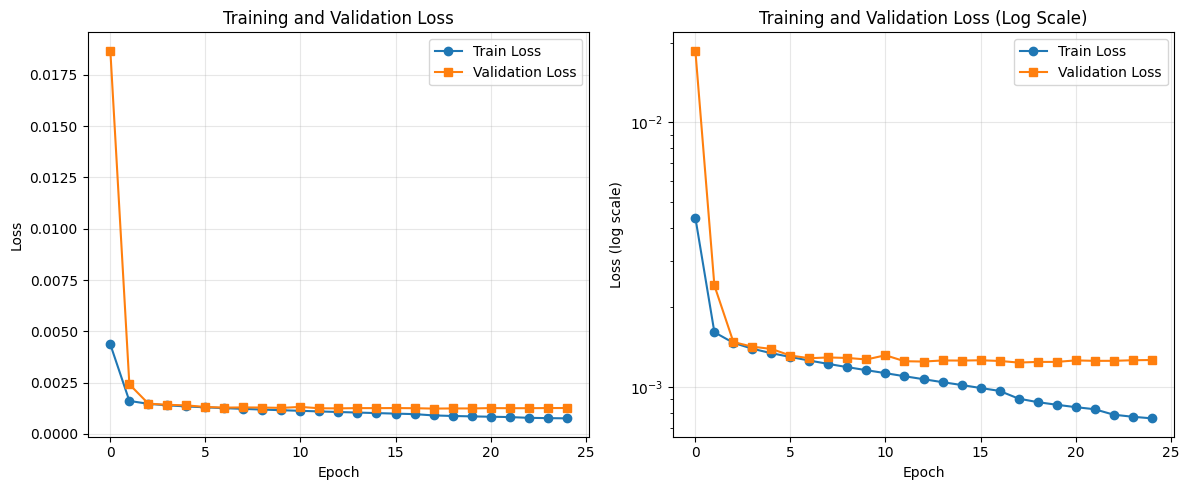

학습 곡선 저장 완료: training_curves.png


In [24]:
# 학습 곡선 그리기
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.yscale('log')
plt.title('Training and Validation Loss (Log Scale)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(BASE_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print("학습 곡선 저장 완료: training_curves.png")

## 8.5. Validation Set 성능 평가

학습된 모델의 성능을 Validation Set (100 samples)으로 평가합니다.
- **F1-Score (Micro/Macro)**: 다중 라벨 분류 성능
- **Precision / Recall**: 정밀도와 재현율
- **Average Precision**: 순위 기반 성능


In [1]:
# =========================================================================
# Validation Set 성능 평가 (CAFA6 Weighted F-max 포함, GPU 병렬 처리)
# =========================================================================
from sklearn.metrics import (
    f1_score, precision_score, recall_score, 
    average_precision_score, hamming_loss,
    multilabel_confusion_matrix
)
import torch
from torch.utils.data import DataLoader

print("=" * 70)
print("📊 Validation Set 성능 평가 (CAFA6 Weighted F-max 포함, GPU 병렬)")
print("=" * 70)

# 평가용 DataLoader (GPU 최적화, num_workers=8)
val_loader_gpu = DataLoader(
    val_dataset,
    batch_size=256,  # GPU 메모리 허용 범위 내에서 크게
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    worker_init_fn=worker_init_fn,
    collate_fn=collate_fn_train,
    persistent_workers=True
)

# 모델을 평가 모드로 설정
model.eval()

# GPU 병렬 추론 함수 (batch 단위, no_grad, device 활용)
def predict_gpu(model, loader, device):
    preds = []
    with torch.no_grad():
        for batch in loader:
            emb = batch['embedding'].to(device, non_blocking=True)
            attn = batch['attention_mask'].to(device, non_blocking=True)
            # 모델이 attention_mask를 받지 않으면 제거
            try:
                logits = model(emb, attention_mask=attn)
            except TypeError:
                logits = model(emb)
            preds.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(preds, axis=0)

print("\n🔮 Validation 데이터 예측 중 (GPU 병렬)...")
val_predictions = predict_gpu(model, val_loader_gpu, device)
print(f"  예측 shape: {val_predictions.shape}")

y_val_true = y_val  # 데이터셋 구성 셀에서 생성된 y_val 사용
print(f"  실제 라벨 shape: {y_val_true.shape}")

# ⭐ CAFA6 공식 평가 지표: Weighted F-max & S-min
print("\n" + "=" * 70)
print("⭐ CAFA6 공식 평가 지표 (Weighted F-max)")
print("=" * 70)

if ic_weights_np is not None:
    cafa6_results = evaluate_cafa6_metrics(
        preds=val_predictions,
        labels=y_val_true,
        ia_weights=ic_weights_np,
        thresholds=np.linspace(0, 1, 101),
        verbose=True
    )
    print(f"\n📈 Weighted F-max 세부 정보:")
    print(f"   최적 임계값: {cafa6_results['fmax_threshold']:.2f}")
    print(f"   F-max 점수: {cafa6_results['fmax']:.4f}")
    print(f"   S-min 점수: {cafa6_results['smin']:.4f} (낮을수록 좋음)")
else:
    print("⚠️ IC 가중치가 로드되지 않아 Weighted F-max 계산 불가")
    print("   USE_IC_WEIGHTED_LOSS = True 로 설정하고 다시 실행하세요.")

# 다양한 임계값에서 성능 평가
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]
results = []

print("\n" + "=" * 70)
print("📈 임계값별 성능 비교")
print("=" * 70)
print(f"{'Threshold':<12} {'F1-Micro':<12} {'F1-Macro':<12} {'Precision':<12} {'Recall':<12} {'Hamming':<12}")
print("-" * 70)

for threshold in thresholds:
    y_pred_binary = (val_predictions >= threshold).astype(int)
    f1_micro = f1_score(y_val_true, y_pred_binary, average='micro', zero_division=0)
    f1_macro = f1_score(y_val_true, y_pred_binary, average='macro', zero_division=0)
    precision = precision_score(y_val_true, y_pred_binary, average='micro', zero_division=0)
    recall = recall_score(y_val_true, y_pred_binary, average='micro', zero_division=0)
    hamming = hamming_loss(y_val_true, y_pred_binary)
    results.append({
        'threshold': threshold,
        'f1_micro': f1_micro,
        'f1_macro': f1_macro,
        'precision': precision,
        'recall': recall,
        'hamming_loss': hamming
    })
    print(f"{threshold:<12.1f} {f1_micro:<12.4f} {f1_macro:<12.4f} {precision:<12.4f} {recall:<12.4f} {hamming:<12.6f}")

best_result = max(results, key=lambda x: x['f1_micro'])
print("-" * 70)
print(f"✅ 최적 임계값: {best_result['threshold']} (F1-Micro: {best_result['f1_micro']:.4f})")

# Average Precision Score (순위 기반 메트릭)
print("\n" + "=" * 70)
print("📊 Average Precision Score (순위 기반)")
print("=" * 70)
positive_classes = np.where(y_val_true.sum(axis=0) > 0)[0]
print(f"  Positive 샘플이 있는 클래스 수: {len(positive_classes)} / {y_val_true.shape[1]}")
if len(positive_classes) > 0:
    ap_scores = []
    for cls_idx in positive_classes:
        try:
            ap = average_precision_score(y_val_true[:, cls_idx], val_predictions[:, cls_idx])
            if not np.isnan(ap):
                ap_scores.append(ap)
        except:
            pass
    if ap_scores:
        mean_ap = np.mean(ap_scores)
        print(f"  Mean Average Precision (mAP): {mean_ap:.4f}")
        print(f"  AP 분포: min={np.min(ap_scores):.4f}, max={np.max(ap_scores):.4f}, std={np.std(ap_scores):.4f}")

# 예측 통계
print("\n" + "=" * 70)
print("📈 예측 통계")
print("=" * 70)
best_threshold = best_result['threshold']
y_pred_best = (val_predictions >= best_threshold).astype(int)
print(f"  임계값: {best_threshold}")
print(f"  샘플당 평균 예측 GO Terms: {y_pred_best.sum(axis=1).mean():.2f}")
print(f"  샘플당 평균 실제 GO Terms: {y_val_true.sum(axis=1).mean():.2f}")
print(f"  예측 확률 분포: min={val_predictions.min():.4f}, max={val_predictions.max():.4f}, mean={val_predictions.mean():.4f}")

# 결과 시각화
print("\n" + "=" * 70)
print("📊 성능 시각화")
print("=" * 70)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax1 = axes[0]
thresholds_list = [r['threshold'] for r in results]
f1_micro_list = [r['f1_micro'] for r in results]
f1_macro_list = [r['f1_macro'] for r in results]
ax1.plot(thresholds_list, f1_micro_list, 'b-o', label='F1-Micro', linewidth=2)
ax1.plot(thresholds_list, f1_macro_list, 'r-s', label='F1-Macro', linewidth=2)
ax1.set_xlabel('Threshold')
ax1.set_ylabel('F1 Score')
ax1.set_title('F1 Score vs Threshold')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax2 = axes[1]
precision_list = [r['precision'] for r in results]
recall_list = [r['recall'] for r in results]
ax2.plot(thresholds_list, precision_list, 'g-o', label='Precision', linewidth=2)
ax2.plot(thresholds_list, recall_list, 'm-s', label='Recall', linewidth=2)
ax2.set_xlabel('Threshold')
ax2.set_ylabel('Score')
ax2.set_title('Precision-Recall vs Threshold')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax3 = axes[2]
ax3.hist(val_predictions.flatten(), bins=50, edgecolor='black', alpha=0.7)
ax3.axvline(x=best_threshold, color='r', linestyle='--', label=f'Best Threshold={best_threshold}')
ax3.set_xlabel('Predicted Probability')
ax3.set_ylabel('Frequency')
ax3.set_title('Prediction Probability Distribution')
ax3.legend()
ax3.set_yscale('log')
plt.tight_layout()
plt.savefig(OUT_DIR / 'validation_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Validation 평가 완료!")
print(f"   그래프 저장: validation_evaluation.png")

📊 Validation Set 성능 평가 (CAFA6 Weighted F-max 포함, GPU 병렬)


NameError: name 'val_dataset' is not defined

## 9. 테스트 데이터 예측

In [ ]:
# =========================================================================
# 최고 성능 1D CNN 모델 로드
# =========================================================================
print("=" * 70)
print("📥 최고 성능 1D CNN 모델 로드 중...")
print("=" * 70)

checkpoint = torch.load(MODEL_SAVE_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"\n✅ 모델 로드 완료!")
print(f"  📁 파일: {MODEL_SAVE_PATH}")
print(f"  📊 Epoch: {checkpoint['epoch'] + 1}")
print(f"  📉 Train Loss: {checkpoint['train_loss']:.4f}")
print(f"  📉 Validation Loss: {checkpoint['val_loss']:.4f}")

if 'model_config' in checkpoint:
    print(f"\n📐 모델 설정:")
    for key, value in checkpoint['model_config'].items():
        print(f"    {key}: {value}")

최고 성능 모델 로드 중...
로드된 모델 정보:
  Epoch: 48
  Train Loss: 0.0132
  Validation Loss: 0.0179


In [ ]:
# =========================================================================
# 테스트 데이터 예측 (1D CNN + DataLoader 사용)
# =========================================================================
print("=" * 70)
print("🔮 테스트 데이터 예측 중...")
print("=" * 70)

# predict 함수를 사용하여 예측 수행
test_predictions = predict(model, test_loader, device)

print(f"\n✅ 예측 완료!")
print(f"  예측 shape: {test_predictions.shape}")
print(f"  평균 확률: {test_predictions.mean():.4f}")
print(f"  최대 확률: {test_predictions.max():.4f}")


테스트 데이터 예측 중...


예측:   0%|          | 0/4 [00:00<?, ?it/s]

예측 완료! Shape: (100, 40122)


In [ ]:
# =========================================================================
# 계층적 제약조건 적용 (비활성화)
# =========================================================================
# 계층적 제약조건은 데이터 오염 문제로 사용하지 않습니다.
# 모델의 순수 예측값을 직접 사용합니다.
# =========================================================================

print("=" * 70)
print("📊 예측 결과 요약 (계층적 제약조건 비활성화)")
print("=" * 70)
print(f"  예측 shape: {test_predictions.shape}")
print(f"  평균 확률: {test_predictions.mean():.4f}")
print(f"  최소 확률: {test_predictions.min():.4f}")
print(f"  최대 확률: {test_predictions.max():.4f}")
print(f"\n✅ 모델의 순수 예측값을 사용합니다.")


계층적 제약조건 적용 중...
양방향 계층적 제약조건 적용
  설정:
    - 전파 임계값: 0.5
    - 전파 비율: 0.3 (30%)
  원본 평균 확률: 0.0137

[Phase 1] Bottom-Up 조건부 전파...
    반복 1: 4009133개 업데이트
    반복 2: 0개 업데이트
  ✓ Bottom-Up 수렴 완료 (2회 반복)
  Bottom-Up 후 평균 확률: 0.2635

[Phase 2] Top-Down 제한 적용...
    반복 1: 10928027개 제한 적용
    반복 2: 52243개 제한 적용
    반복 3: 987개 제한 적용
    반복 4: 94개 제한 적용
    반복 5: 0개 제한 적용
  ✓ Top-Down 수렴 완료 (5회 반복)

결과 요약
  원본 평균 확률:      0.0137
  Bottom-Up 후:        0.2635 (+1827.9%)
  Top-Down 후 (최종):  0.2634 (+1826.5%)
제약조건 적용 완료!
제약조건 적용 전 평균 확률: 0.0137
제약조건 적용 후 평균 확률: 0.2634


## 10. 제출 파일 생성

In [42]:
# 제출 형식 확인
# sample_submission.tsv는 GO Term 행(3컬럼)과 Text 행(4컬럼)이 섞여있음
# GO Term 행만 필터링
print("샘플 제출 파일 로드 중...")

# on_bad_lines='skip'으로 파싱 오류 무시하고 수동으로 처리
sample_rows = []
with open(DATA_DIR / 'sample_submission.tsv', 'r', encoding='utf-8') as f:
    for line in f:
        parts = line.strip().split('\t')
        # GO Term 행만 선택 (3개 컬럼이고 두 번째 컬럼이 GO:로 시작)
        if len(parts) == 3 and parts[1].startswith('GO:'):
            sample_rows.append(parts)

sample_submission = pd.DataFrame(sample_rows, columns=['EntryID', 'GO_Term', 'Probability'])
sample_submission['Probability'] = sample_submission['Probability'].astype(float)

print(f"샘플 제출 파일 (GO Term 행만):")
print(sample_submission.head(10))
print(f"\n총 GO Term 예측 수: {len(sample_submission)}")
print(f"고유 단백질 수: {sample_submission['EntryID'].nunique()}")
print(f"단백질 당 평균 GO Term 수: {len(sample_submission) / sample_submission['EntryID'].nunique():.2f}")

샘플 제출 파일 로드 중...
샘플 제출 파일 (GO Term 행만):
      EntryID     GO_Term  Probability
0  A0A0C5B5G6  GO:0000001        0.123
1  A0A0C5B5G6  GO:0000002        0.456
2  A0A1B0GTW7  GO:0000001        0.123
3  A0A1B0GTW7  GO:0000002        0.456
4      A0JNW5  GO:0000001        0.123
5      A0JNW5  GO:0000002        0.456
6      A0JP26  GO:0000001        0.123
7      A0JP26  GO:0000002        0.456
8      A0PK11  GO:0000001        0.123
9      A0PK11  GO:0000002        0.456

총 GO Term 예측 수: 20000
고유 단백질 수: 10000
단백질 당 평균 GO Term 수: 2.00


In [ ]:
# 제출 파일 생성
print("\n제출 파일 생성 중...")
submission_rows = []

for protein_idx, protein_id in enumerate(tqdm(test_ids, desc="제출 파일 생성")):
    protein_preds = test_predictions[protein_idx]  # 순수 모델 예측값 사용
    
    # 확률이 높은 GO Term들 선택 (threshold 적용)
    threshold = 0.1  # 조정 가능
    predicted_indices = np.where(protein_preds > threshold)[0]
    
    if len(predicted_indices) == 0:
        # 최소한 상위 N개는 포함
        top_n = 10
        predicted_indices = np.argsort(protein_preds)[-top_n:]
    
    for go_idx in predicted_indices:
        go_term = idx_to_term[go_idx]
        prob = protein_preds[go_idx]
        submission_rows.append({
            'EntryID': protein_id,
            'GO_Term': go_term,
            'Probability': prob
        })

submission_df = pd.DataFrame(submission_rows)
print(f"\n제출 파일 통계:")
print(f"  총 예측 수: {len(submission_df)}")
print(f"  단백질 당 평균 예측 수: {len(submission_df) / len(test_ids):.2f}")
print(f"\n샘플:")
print(submission_df.head(40))


제출 파일 생성 중...


제출 파일 생성:   0%|          | 0/100 [00:00<?, ?it/s]


제출 파일 통계:
  총 예측 수: 4012200
  단백질 당 평균 예측 수: 40122.00

샘플:
       EntryID     GO_Term  Probability
0   A0A0C5B5G6  GO:0000001     0.245535
1   A0A0C5B5G6  GO:0000002     0.245535
2   A0A0C5B5G6  GO:0000006     0.273849
3   A0A0C5B5G6  GO:0000007     0.273849
4   A0A0C5B5G6  GO:0000009     0.273849
5   A0A0C5B5G6  GO:0000010     0.273849
6   A0A0C5B5G6  GO:0000011     0.245535
7   A0A0C5B5G6  GO:0000012     0.245535
8   A0A0C5B5G6  GO:0000014     0.273849
9   A0A0C5B5G6  GO:0000015     0.268517
10  A0A0C5B5G6  GO:0000016     0.273849
11  A0A0C5B5G6  GO:0000017     0.245535
12  A0A0C5B5G6  GO:0000018     0.245535
13  A0A0C5B5G6  GO:0000019     0.245535
14  A0A0C5B5G6  GO:0000022     0.245535
15  A0A0C5B5G6  GO:0000023     0.245535
16  A0A0C5B5G6  GO:0000024     0.245535
17  A0A0C5B5G6  GO:0000025     0.245535
18  A0A0C5B5G6  GO:0000026     0.273849
19  A0A0C5B5G6  GO:0000027     0.245535
20  A0A0C5B5G6  GO:0000028     0.245535
21  A0A0C5B5G6  GO:0000030     0.273849
22  A0A0C5B5G6  GO:0

In [ ]:
# 제출 파일 저장
submission_path = BASE_DIR / 'submission.tsv'
submission_df.to_csv(submission_path, sep='\t', index=False)
print(f"\n제출 파일 저장 완료: {submission_path}")
print(f"파일 크기: {submission_path.stat().st_size / 1024 / 1024:.2f} MB")

## 11. 결과 분석

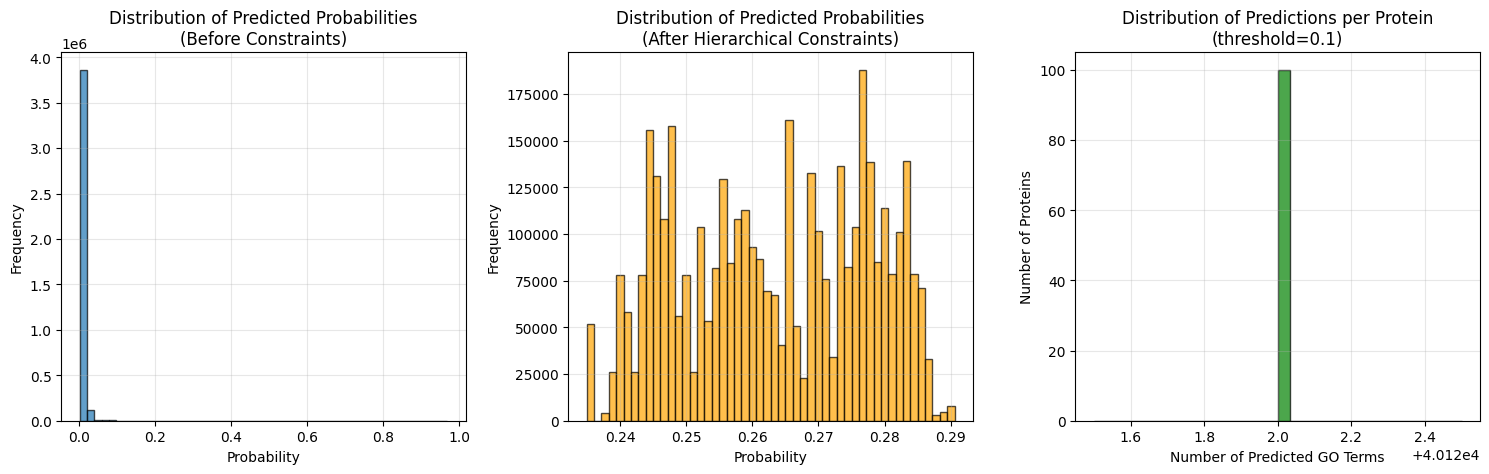

예측 분석 그래프 저장 완료: prediction_analysis.png


In [ ]:
# 예측 확률 분포 확인
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(test_predictions.flatten(), bins=50, alpha=0.7, edgecolor='black', color='steelblue')
plt.xlabel('Probability')
plt.ylabel('Frequency')
plt.title('Distribution of Predicted Probabilities\n(Model Output)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
predictions_per_protein = submission_df.groupby('EntryID').size()
plt.hist(predictions_per_protein, bins=30, alpha=0.7, color='green', edgecolor='black')
plt.xlabel('Number of Predicted GO Terms')
plt.ylabel('Number of Proteins')
plt.title('Distribution of Predictions per Protein\n(threshold=0.1)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(BASE_DIR / 'prediction_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("예측 분석 그래프 저장 완료: prediction_analysis.png")

## 요약

### 완료된 작업
1. ✅ ESM2 임베딩 데이터 로드
2. ✅ GO Term 매핑 및 계층 구조 데이터 로드
3. ✅ Multi-label binary matrix 생성
4. ✅ 계층 구조 기반 라벨 전파 (Propagation)
5. ✅ MLP 기반 딥러닝 모델 구축
6. ✅ 모델 학습 (Train/Validation)
7. ✅ 계층적 제약조건 후처리
8. ✅ 테스트 데이터 예측
9. ✅ 제출 파일 생성

### 다음 단계 개선 사항
- [ ] F-max 기반 Threshold Tuning
- [ ] 앙상블 모델 (여러 모델의 예측 평균)
- [ ] Class Imbalance 처리 (Focal Loss, Class Weights)
- [ ] 더 복잡한 모델 아키텍처 (ResNet, Attention)
- [ ] Homology-based Baseline과의 결합